In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import numpy as np

from formulaic import model_matrix
from sklearn.linear_model import LinearRegression

# Plotting functions

In [2]:
def plot_predictions_fig_noembryo(model, formula, df):
    ss_indx = ~df['species'].isin(["Atlantic salmon", "Rainbow trout"])
    df = df.assign(include=0)
    df.loc[ss_indx, 'include'] = 1
    fig, ax = plt.subplots(1, 2, sharey=True, figsize=(11, 4.5))
    
    y_actual, X = model_matrix(formula, df)
    y_actual = y_actual.values.flatten()

    categories = df["include"]
    line_color = predict_color = "grey"
    wgd_color = "#ff7f0e"
    non_wgd_color = "#1f77b4"
    colors = list(map(lambda x: wgd_color if x==0 else non_wgd_color, categories))
    labels = df["species"]
    [lp, rp] = ax[0:2]

    ## left plot: tissue count
    x_vals = df['pipeline_tissues_with_OC']
    lp.grid(True, linestyle='--', alpha=0.7)

    # plot fit line    
    tissue_count = np.linspace(df['pipeline_tissues_with_OC'].min() - 1, df['pipeline_tissues_with_OC'].max(), 100)
    df_line = pd.DataFrame({
        'peo_count': 0,
        'log_tissue_count': np.log1p(tissue_count),
        'WGD': 0,
        'genome_length': 0,
    })
    _, X_line = model_matrix(formula, df_line)
    y_line = model.predict(X_line)

    lp.scatter(x_vals, y_actual, color=colors)
    lp.plot(tissue_count, y_line, color=non_wgd_color, linestyle = "--")
    for x, y, label in zip(x_vals, y_actual, labels):
        x = x + 0.2
        if label == "Human":
            lp.text(x, y + 5000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        elif label == "Mouse":
            lp.text(x + 0.1, y, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        elif label == "Common carp":
            lp.text(x + 0.5, y + 5000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        elif label == "European seabass":
            lp.text(x + 0.1, y, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        elif label == "Cattle":
            lp.text(x + 0.1, y, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        else:
            lp.text(x, y, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)


    lp.set_ylim(0, 350000)
    lp.set_xlabel('Tissue count')
    lp.set_ylabel('Feature count')

    ## right plot: genome length
    x_vals = df['genome_length']
    rp.grid(True, linestyle='--', alpha=0.7)
    formatter = rp.xaxis.get_major_formatter()
    formatter.set_useMathText(True)

    rp.scatter(x_vals, y_actual, color=colors)
    for x, y, label in zip(x_vals, y_actual, labels):
        x = x + 30000000
        y = y + 1000
        if label == "Human":
            rp.text(x, y + 5000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        else:
            rp.text(x, y, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)
    

    rp.set_xlabel('Genome length')

    from matplotlib.lines import Line2D

    legend_salmonid = Line2D([0], [0], marker='o', linewidth=0, markeredgecolor=wgd_color, 
                           label='Salmonid species', markerfacecolor=wgd_color, markersize=10)
    legend_non_salmonid = Line2D([0], [0], marker='o', linewidth=0, markeredgecolor=non_wgd_color, 
                           label='Non-salmonid species', markerfacecolor=non_wgd_color, markersize=10)
    legend_regression_line = Line2D([0], [0], marker='', color = non_wgd_color,  linestyle="--", label='log(tissue count + 1)',
                          markerfacecolor=line_color, markersize=10)

    fig.legend(handles=[legend_non_salmonid, legend_salmonid, legend_regression_line],
           loc='upper center', bbox_to_anchor=(0.5, 0), ncol=3,
           fancybox=True, shadow=True, borderpad=1)  

    fig.tight_layout()  
    return fig

In [3]:
def plot_predictions_fig_withembryo(model, formula, df):
    ss_indx = ~df['species'].isin(["Atlantic salmon", "Rainbow trout"])
    df = df.assign(include=0)
    df.loc[ss_indx, 'include'] = 1
    fig, ax = plt.subplots(1, 2, sharey=True, figsize=(11, 4.5))
    
    y_actual, X = model_matrix(formula, df)
    y_actual = y_actual.values.flatten()

    categories = df["include"]
    line_color = predict_color = "grey"
    wgd_color = "#ff7f0e"
    non_wgd_color = "#1f77b4"
    colors = list(map(lambda x: wgd_color if x==0 else non_wgd_color, categories))
    labels = df["species"]
    [lp, rp] = ax[0:2]

    ## left plot: tissue count
    x_vals = df['pipeline_tissues_with_OC']
    lp.grid(True, linestyle='--', alpha=0.7)

    # plot fit line    
    tissue_count = np.linspace(df['pipeline_tissues_with_OC'].min() - 1, df['pipeline_tissues_with_OC'].max(), 100)
    df_line = pd.DataFrame({
        'peo_count': 0,
        'log_tissue_count': np.log1p(tissue_count),
        'WGD': 0,
        'genome_length': 0,
    })
    _, X_line = model_matrix(formula, df_line)
    y_line = model.predict(X_line)

    lp.scatter(x_vals, y_actual, color=colors)
    lp.plot(tissue_count, y_line, color=non_wgd_color, linestyle = "--")
    for x, y, label in zip(x_vals, y_actual, labels):
        x = x + 0.2
        if label == "Human":
            lp.text(x, y + 5000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        elif label == "Mouse":
            lp.text(x, y - 5000, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        elif label == "Common carp":
            lp.text(x + 1, y + 5000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        elif label == "European seabass":
            lp.text(x + 0.1, y - 5000, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        elif label == "Cattle":
            lp.text(x + 0.1, y, str(label), fontsize=9, ha='left', va='center', alpha=0.8)
        else:
            lp.text(x, y, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)

    lp.set_ylim(0, 350000)
    lp.set_xlabel('Tissue count')
    lp.set_ylabel('Feature count')

    ## right plot: genome length
    x_vals = df['genome_length']
    rp.grid(True, linestyle='--', alpha=0.7)
    formatter = rp.xaxis.get_major_formatter()
    formatter.set_useMathText(True)

    rp.scatter(x_vals, y_actual, color=colors)
    for x, y, label in zip(x_vals, y_actual, labels):
        x = x + 30000000
        if label == "Pig":
            rp.text(x, y - 15000, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)
        elif label == "Rainbow trout":
            rp.text(x, y + 5000, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)
        elif label == "Human":
            rp.text(x, y + 10000, str(label), fontsize=9, ha='right', va='bottom', alpha=0.8)
        else:
            rp.text(x, y, str(label), fontsize=9, ha='left', va='bottom', alpha=0.8)
    

    rp.set_xlabel('Genome length')

    from matplotlib.lines import Line2D

    legend_salmonid = Line2D([0], [0], marker='o', linewidth=0, markeredgecolor=wgd_color, 
                           label='Salmonid species', markerfacecolor=wgd_color, markersize=10)
    legend_non_salmonid = Line2D([0], [0], marker='o', linewidth=0, markeredgecolor=non_wgd_color, 
                           label='Non-salmonid species', markerfacecolor=non_wgd_color, markersize=10)
    legend_regression_line = Line2D([0], [0], marker='', color = non_wgd_color,  linestyle="--", label='log(tissue count)',
                          markerfacecolor=line_color, markersize=10)

    fig.legend(handles=[legend_non_salmonid, legend_salmonid, legend_regression_line],
           loc='upper center', bbox_to_anchor=(0.5, 0), ncol=3,
           fancybox=True, shadow=True, borderpad=1)  

    fig.tight_layout()  
    return fig

# Plots

In [4]:
df_noembryo = pd.read_csv("data/df_agg_no_embryo.csv")
df_noembryo = df_noembryo[df_noembryo["assembly"] != "GRCh37"]
df_noembryo["log_tissue_count"] = np.log1p(df_noembryo["pipeline_tissues_with_OC"])
df_noembryo

,assembly,pe_count,peo_count,species,embryo_data,genome_length,genome_coding_length,coding_gene_count,non_coding_gene_count,all_gene_count,pipeline_gene_count,pipeline_tissues_with_OC,genome_gap_length,log_tissue_count
0,ARS-UCD2.0,85301,116156,Cattle,False,2.663142e+09,34667422,20849,16732,37581,33673.0,6.0,28162,1.945910
1,ASM1334776v1,35485,59706,Turbot,True,5.136205e+08,36534184,21263,12989,34252,22182.0,4.0,2160,1.609438
2,Cypcar_WagV4.0,57475,118358,Common carp,False,1.423737e+09,78076182,44807,9749,54556,52768.0,5.0,37200,1.791759
3,GRCg7b,127615,212472,Chicken,True,1.016975e+09,30000483,17007,13040,30047,28418.0,13.0,3383918,2.639057
5,GRCh38,269511,276834,Human,True,3.028164e+09,34493611,20481,25959,46440,54578.0,18.0,161611139,2.944439
6,GRCm39,183146,196695,Mouse,True,2.728125e+09,36296917,22178,17718,39896,54478.0,11.0,73600614,2.484907
7,Ssal_v3.1,164535,261676,Atlantic salmon,True,2.300842e+09,78093896,47205,21576,68781,55842.0,4.0,21100,1.609438
8,Sscrofa11.1,143338,201717,Pig,True,2.403606e+09,34389280,22063,13154,35217,31733.0,9.0,29864641,2.302585
9,USDA_OmykA_1.1,90321,174714,Rainbow trout,True,1.991763e+09,85521654,48326,15627,63953,49260.0,4.0,6184519,1.609438
10,dlabrax2021,58082,83160,European seabass,True,6.650850e+08,41106531,23006,1836,24842,23751.0,5.0,1022065,1.791759


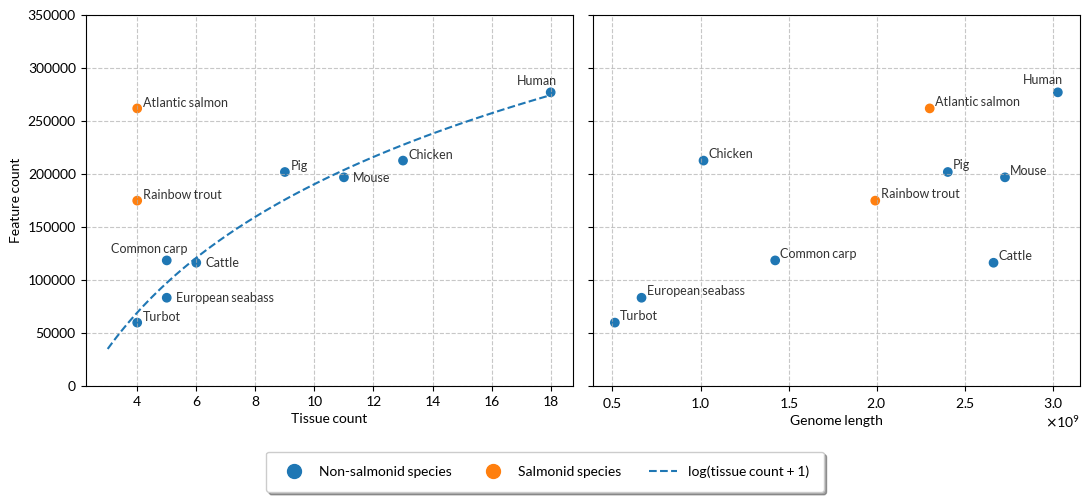

In [5]:
df_ss_noembryo = df_noembryo[~df_noembryo["species"].isin(["Rainbow trout", "Atlantic salmon"])]
formula1 = "peo_count ~ -1 + log_tissue_count"
y, X = model_matrix(formula1, df_ss_noembryo)
model1 = LinearRegression().fit(X, y)
fig = plot_predictions_fig_noembryo(model1, formula1, df_noembryo)
fig.savefig("exports/feature_count_trend_noembryo.svg", dpi=600, bbox_inches="tight")

In [6]:
df_withembryo = pd.read_csv("data/df_agg_with_embryo.csv")
df_withembryo = df_withembryo[df_withembryo["assembly"] != "GRCh37"]
df_withembryo["log_tissue_count"] = np.log1p(df_withembryo["pipeline_tissues_with_OC"])
df_withembryo

,assembly,pe_count,peo_count,species,embryo_data,genome_length,genome_coding_length,coding_gene_count,non_coding_gene_count,all_gene_count,pipeline_gene_count,pipeline_tissues_with_OC,genome_gap_length,log_tissue_count
0,ARS-UCD2.0,85301,116156,Cattle,False,2.663142e+09,34667422,20849,16732,37581,33673.0,6.0,28162,1.945910
1,ASM1334776v1,37754,67556,Turbot,True,5.136205e+08,36534184,21263,12989,34252,22182.0,5.0,2160,1.791759
2,Cypcar_WagV4.0,57475,118358,Common carp,False,1.423737e+09,78076182,44807,9749,54556,52768.0,5.0,37200,1.791759
3,GRCg7b,127615,212472,Chicken,True,1.016975e+09,30000483,17007,13040,30047,28418.0,13.0,3383918,2.639057
5,GRCh38,282386,289927,Human,True,3.028164e+09,34493611,20481,25959,46440,54578.0,19.0,161611139,2.995732
6,GRCm39,192793,206470,Mouse,True,2.728125e+09,36296917,22178,17718,39896,54478.0,12.0,73600614,2.564949
7,Ssal_v3.1,227914,324075,Atlantic salmon,True,2.300842e+09,78093896,47205,21576,68781,55842.0,5.0,21100,1.791759
8,Sscrofa11.1,143338,201717,Pig,True,2.403606e+09,34389280,22063,13154,35217,31733.0,9.0,29864641,2.302585
9,USDA_OmykA_1.1,131098,204166,Rainbow trout,True,1.991763e+09,85521654,48326,15627,63953,49260.0,5.0,6184519,1.791759
10,dlabrax2021,68662,112774,European seabass,True,6.650850e+08,41106531,23006,1836,24842,23751.0,6.0,1022065,1.945910


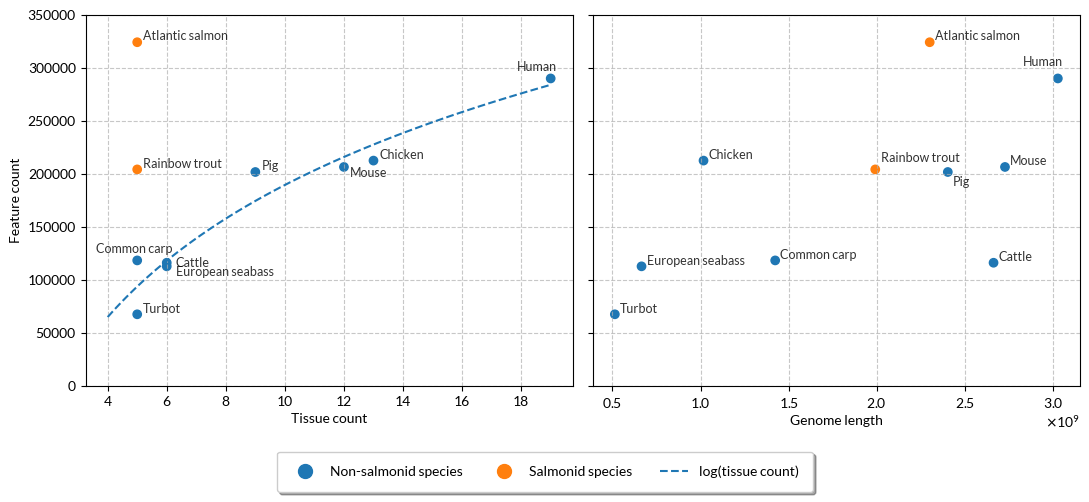

In [7]:
df_ss_withembryo = df_withembryo[~df_withembryo["species"].isin(["Rainbow trout", "Atlantic salmon"])]
formula1 = "peo_count ~ -1 + log_tissue_count"
y, X = model_matrix(formula1, df_ss_withembryo)
model1 = LinearRegression().fit(X, y)
fig = plot_predictions_fig_withembryo(model1, formula1, df_withembryo)
fig.savefig("exports/feature_count_trend_withembryo.svg", dpi=600, bbox_inches="tight")

In [8]:
import statsmodels.formula.api as smf
model1 = smf.ols('peo_count ~ log_tissue_count', data=df_ss_noembryo).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:              peo_count   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.949
Method:                 Least Squares   F-statistic:                     130.9
Date:                Mon, 27 Oct 2025   Prob (F-statistic):           2.67e-05
Time:                        13:42:53   Log-Likelihood:                -88.078
No. Observations:                   8   AIC:                             180.2
Df Residuals:                       6   BIC:                             180.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         -1.78e+05      3e+04  